#SECTION B — PRACTICAL CODING TASKS

In [1]:
#TASK 1 — DELIVERY FEE ARRAY CALCULATOR (NumPy)

#ANSWER:

import numpy as np

# Fixed random seed
np.random.seed(42)

# Generate 25 random delivery distances
distances = np.random.uniform(1.0, 15.0, 25)

# Calculate delivery fee using vectorised operation
fees = 20 + 5 * distances

# Boolean indexing for fees greater than Rs 60
mask = fees > 60

print("Orders with Delivery Fee Greater Than Rs 60")
print("--------------------------------------------")
print("Distance (km)    Fee (Rs)")
print(np.column_stack((distances[mask], fees[mask])))

# Calculate statistics
print("\nFee Statistics")
print("--------------")
print(f"Minimum Fee        : Rs {np.min(fees):.2f}")
print(f"Maximum Fee        : Rs {np.max(fees):.2f}")
print(f"Mean Fee           : Rs {np.mean(fees):.2f}")
print(f"Standard Deviation : Rs {np.std(fees):.2f}")

Orders with Delivery Fee Greater Than Rs 60
--------------------------------------------
Distance (km)    Fee (Rs)
[[14.31000029 91.55000145]
 [11.24791519 76.23957593]
 [ 9.38121878 66.90609389]
 [13.12646604 85.6323302 ]
 [ 9.41561016 67.07805082]
 [10.91301609 74.56508045]
 [14.57873793 92.89368965]
 [12.65419697 83.27098486]
 [ 8.34659004 61.73295021]
 [ 9.56594053 67.82970263]]

Fee Statistics
--------------
Minimum Fee        : Rs 26.44
Maximum Fee        : Rs 92.89
Mean Fee           : Rs 55.86
Standard Deviation : Rs 19.56


In [2]:
#TASK 2 — RESTAURANT PERFORMANCE ANALYSER

#ANSWER:

import pandas as pd

# Create food delivery dataset with 40 rows
data = {
    "restaurant_name": [
        "Spice Hub", "Spice Hub", "Spice Hub", "Spice Hub", "Spice Hub",
        "Spice Hub", "Spice Hub", "Spice Hub",
        "Urban Bites", "Urban Bites", "Urban Bites", "Urban Bites", "Urban Bites",
        "Urban Bites", "Urban Bites", "Urban Bites",
        "Food Corner", "Food Corner", "Food Corner", "Food Corner", "Food Corner",
        "Food Corner", "Food Corner", "Food Corner",
        "Tasty Treat", "Tasty Treat", "Tasty Treat", "Tasty Treat", "Tasty Treat",
        "Tasty Treat", "Tasty Treat", "Tasty Treat",
        "Royal Kitchen", "Royal Kitchen", "Royal Kitchen", "Royal Kitchen",
        "Royal Kitchen", "Royal Kitchen", "Royal Kitchen", "Royal Kitchen"
    ],

    "city": [
        "Surat", "Mumbai", "Ahmedabad", "Surat", "Mumbai", "Ahmedabad", "Surat", "Mumbai",
        "Ahmedabad", "Surat", "Mumbai", "Ahmedabad", "Surat", "Mumbai", "Ahmedabad", "Surat",
        "Mumbai", "Ahmedabad", "Surat", "Mumbai", "Ahmedabad", "Surat", "Mumbai", "Ahmedabad",
        "Surat", "Mumbai", "Ahmedabad", "Surat", "Mumbai", "Ahmedabad", "Surat", "Mumbai",
        "Ahmedabad", "Surat", "Mumbai", "Ahmedabad", "Surat", "Mumbai", "Ahmedabad", "Surat"
    ],

    "order_value": [
        450, 520, 380, 600, 490, 550, 420, 580,
        650, 720, 580, 690, 750, 620, 700, 680,
        350, 420, 390, 480, 450, 520, 410, 470,
        800, 720, 760, 850, 690, 780, 820, 740,
        550, 620, 580, 640, 600, 670, 590, 630
    ],

    "delivery_time_mins": [
        28, 30, 32, 29, 31, 27, 33, 30,
        25, 28, 31, 27, 29, 30, 26, 32,
        36, 38, 35, 40, 37, 39, 34, 36,
        24, 27, 29, 26, 28, 25, 30, 27,
        32, 34, 31, 33, 30, 35, 32, 31
    ],

    "rating": [
        4.5, 4.3, 4.6, 4.4, 4.7, 4.2, 4.5, 4.6,
        4.4, 4.6, 4.3, 4.5, 4.7, 4.2, 4.6, 4.4,
        3.8, 3.9, 4.0, 3.7, 3.9, 4.1, 3.8, 4.0,
        4.8, 4.6, 4.7, 4.9, 4.5, 4.8, 4.6, 4.7,
        4.1, 4.3, 4.2, 4.4, 4.0, 4.5, 4.2, 4.3
    ],

    "cuisine_type": [
        "Indian", "Chinese", "Indian", "Fast Food", "Indian", "Chinese", "Fast Food", "Indian",
        "Chinese", "Indian", "Fast Food", "Chinese", "Indian", "Fast Food", "Chinese", "Indian",
        "Fast Food", "Indian", "Chinese", "Fast Food", "Indian", "Chinese", "Fast Food", "Indian",
        "Indian", "Chinese", "Fast Food", "Indian", "Chinese", "Fast Food", "Indian", "Chinese",
        "Indian", "Fast Food", "Chinese", "Indian", "Fast Food", "Chinese", "Indian", "Fast Food"
    ]
}

df = pd.DataFrame(data)

# Group, aggregate, filter and sort
result = (
    df.groupby("restaurant_name")
      .agg(
          mean_order_value=("order_value", "mean"),
          mean_delivery_time=("delivery_time_mins", "mean"),
          mean_rating=("rating", "mean")
      )
      .query("mean_rating > 4.0 and mean_delivery_time < 35")
      .sort_values("mean_order_value", ascending=False)
      .reset_index()
)

print("Restaurant Performance Summary")
print("==============================")
print(result.to_string(index=False))

Restaurant Performance Summary
restaurant_name  mean_order_value  mean_delivery_time  mean_rating
    Tasty Treat            770.00               27.00       4.7000
    Urban Bites            673.75               28.50       4.4625
  Royal Kitchen            610.00               32.25       4.2500
      Spice Hub            498.75               30.00       4.4750


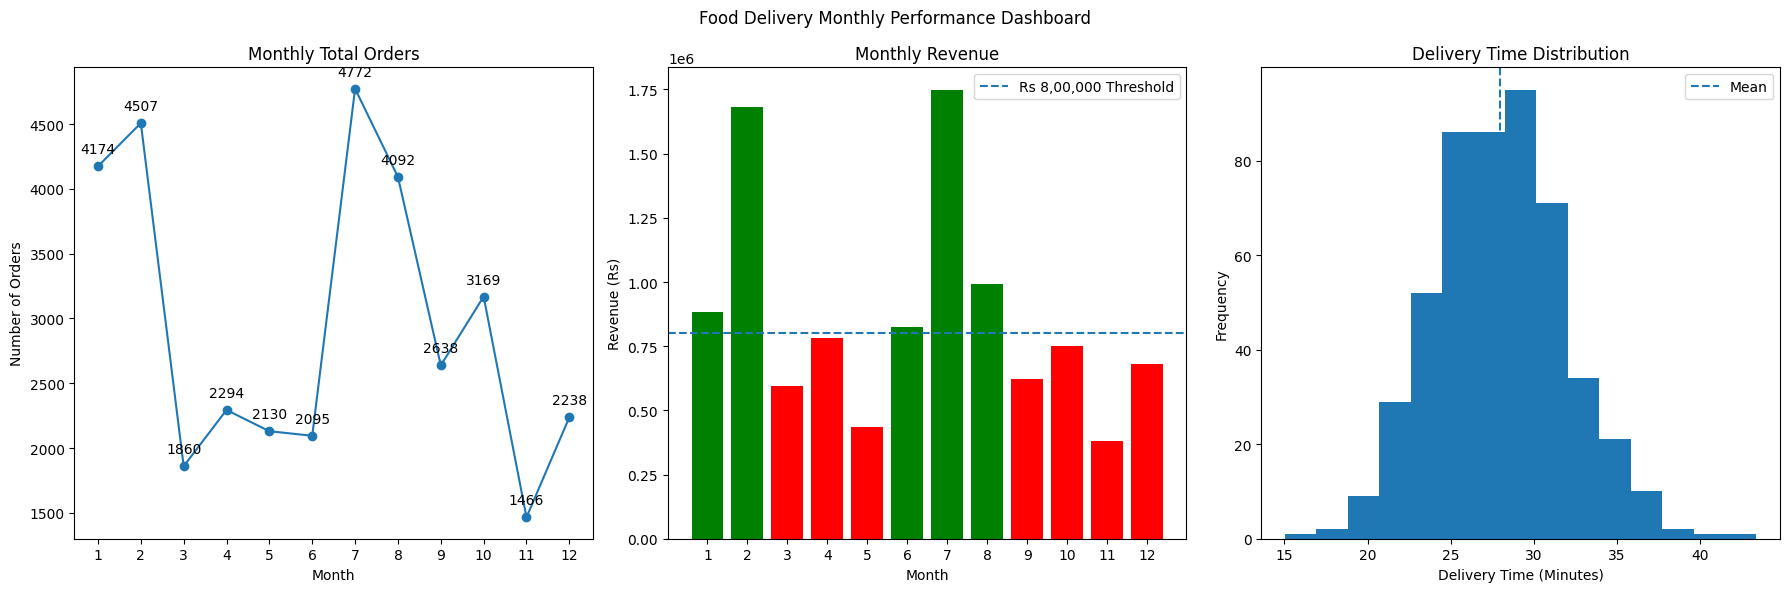

In [3]:
#TASK 3 — MONTHLY ORDER TREND DASHBOARD

#ANSWER:

import numpy as np
import matplotlib.pyplot as plt

# Fixed seed for reproducible results
np.random.seed(42)

# 12 months
months = np.arange(1, 13)

# Generate monthly total orders
orders = np.random.randint(1000, 5001, 12)

# Generate average order value
average_order_value = np.random.uniform(200, 400, 12)

# Calculate monthly revenue
revenue = orders * average_order_value

# Generate 500 delivery times
delivery_times = np.random.normal(28, 4, 500)

# Create figure with 3 subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# -------------------------------
# Subplot 1: Monthly Orders
# -------------------------------
axes[0].plot(
    months,
    orders,
    marker="o"
)

for i in range(12):
    axes[0].text(
        months[i],
        orders[i] + 100,
        str(orders[i]),
        ha="center"
    )

axes[0].set_title("Monthly Total Orders")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Number of Orders")
axes[0].set_xticks(months)

# -------------------------------
# Subplot 2: Monthly Revenue
# -------------------------------
bar_colors = np.where(revenue > 800000, "green", "red")

axes[1].bar(
    months,
    revenue,
    color=bar_colors
)

axes[1].axhline(
    800000,
    linestyle="--",
    label="Rs 8,00,000 Threshold"
)

axes[1].set_title("Monthly Revenue")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Revenue (Rs)")
axes[1].set_xticks(months)
axes[1].legend()

# -------------------------------
# Subplot 3: Delivery Time
# -------------------------------
axes[2].hist(
    delivery_times,
    bins=15
)

sample_mean = np.mean(delivery_times)

axes[2].axvline(
    sample_mean,
    linestyle="--",
    label="Mean"
)

axes[2].set_title("Delivery Time Distribution")
axes[2].set_xlabel("Delivery Time (Minutes)")
axes[2].set_ylabel("Frequency")
axes[2].legend()

# Overall figure title
fig.suptitle("Food Delivery Monthly Performance Dashboard")

# Adjust layout
plt.tight_layout()

# Save figure
plt.savefig(
    "food_delivery_dashboard.png",
    dpi=150
)

plt.show()

In [4]:
#TASK 4 — FULL EDA PIPELINE: FOOD DELIVERY INSIGHTS

#ANSWER:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Fixed seed
np.random.seed(7)

# -------------------------------
# Generate 200-row dataset
# -------------------------------

n = 200

order_value = np.random.uniform(100, 800, n)
distance_km = np.random.uniform(1, 20, n)
delivery_time_mins = np.random.normal(30, 8, n)
rating = np.random.uniform(1.0, 5.0, n)
discount_pct = np.random.uniform(0, 30, n)

# Create DataFrame
df = pd.DataFrame({
    "order_value": order_value,
    "distance_km": distance_km,
    "delivery_time_mins": delivery_time_mins,
    "rating": rating,
    "discount_pct": discount_pct
})

# -------------------------------
# Introduce 5% null values
# -------------------------------

null_count = int(0.05 * n)

delivery_null_indices = np.random.choice(
    df.index,
    size=null_count,
    replace=False
)

rating_null_indices = np.random.choice(
    df.index,
    size=null_count,
    replace=False
)

df.loc[delivery_null_indices, "delivery_time_mins"] = np.nan
df.loc[rating_null_indices, "rating"] = np.nan

# -------------------------------
# Fill nulls with medians
# -------------------------------

df["delivery_time_mins"] = df["delivery_time_mins"].fillna(
    df["delivery_time_mins"].median()
)

df["rating"] = df["rating"].fillna(
    df["rating"].median()
)

# -------------------------------
# Derived column
# -------------------------------

df["delivery_speed_kmph"] = (
    df["distance_km"] /
    (df["delivery_time_mins"] / 60)
)

# -------------------------------
# Speed band using qcut
# -------------------------------

df["speed_band"] = pd.qcut(
    df["delivery_speed_kmph"],
    q=3,
    labels=["Slow", "Normal", "Fast"]
)

# -------------------------------
# Correlation Heatmap
# -------------------------------

numeric_columns = df.select_dtypes(
    include=np.number
).columns

correlation_matrix = df[numeric_columns].corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Food Delivery Correlation Heatmap")
plt.tight_layout()

plt.savefig(
    "correlation_heatmap.png",
    dpi=150
)

plt.close()

# -------------------------------
# Pairplot
# -------------------------------

pairplot = sns.pairplot(
    df[
        [
            "order_value",
            "distance_km",
            "delivery_time_mins",
            "rating",
            "speed_band"
        ]
    ],
    hue="speed_band"
)

pairplot.fig.suptitle(
    "Food Delivery Pairplot",
    y=1.02
)

pairplot.fig.savefig(
    "pairplot.png",
    dpi=150,
    bbox_inches="tight"
)

plt.close()

# -------------------------------
# Display final information
# -------------------------------

print("Food Delivery EDA Completed")
print("===========================")

print("\nDataset Shape:")
print(df.shape)

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

print("\nFirst 5 Rows:")
print(df.head())

print("\nSpeed Band Counts:")
print(df["speed_band"].value_counts())

Food Delivery EDA Completed

Dataset Shape:
(200, 7)

Missing Values After Cleaning:
order_value            0
distance_km            0
delivery_time_mins     0
rating                 0
discount_pct           0
delivery_speed_kmph    0
speed_band             0
dtype: int64

First 5 Rows:
   order_value  distance_km  delivery_time_mins    rating  discount_pct  \
0   153.415803    15.287118           29.436359  1.610398     17.079069   
1   645.943155     2.171641           41.143419  1.247733      4.256927   
2   406.886462    15.151650           20.002291  3.033249     18.347489   
3   606.425624    18.979243           18.019293  3.033249     29.233717   
4   784.592658    12.467631           24.767687  3.171931      8.202608   

   delivery_speed_kmph speed_band  
0            31.159664       Fast  
1             3.166934       Slow  
2            45.449742       Fast  
3            63.196404       Fast  
4            30.202978       Fast  

Speed Band Counts:
speed_band
Slow      67
F

Food Delivery Dashboard


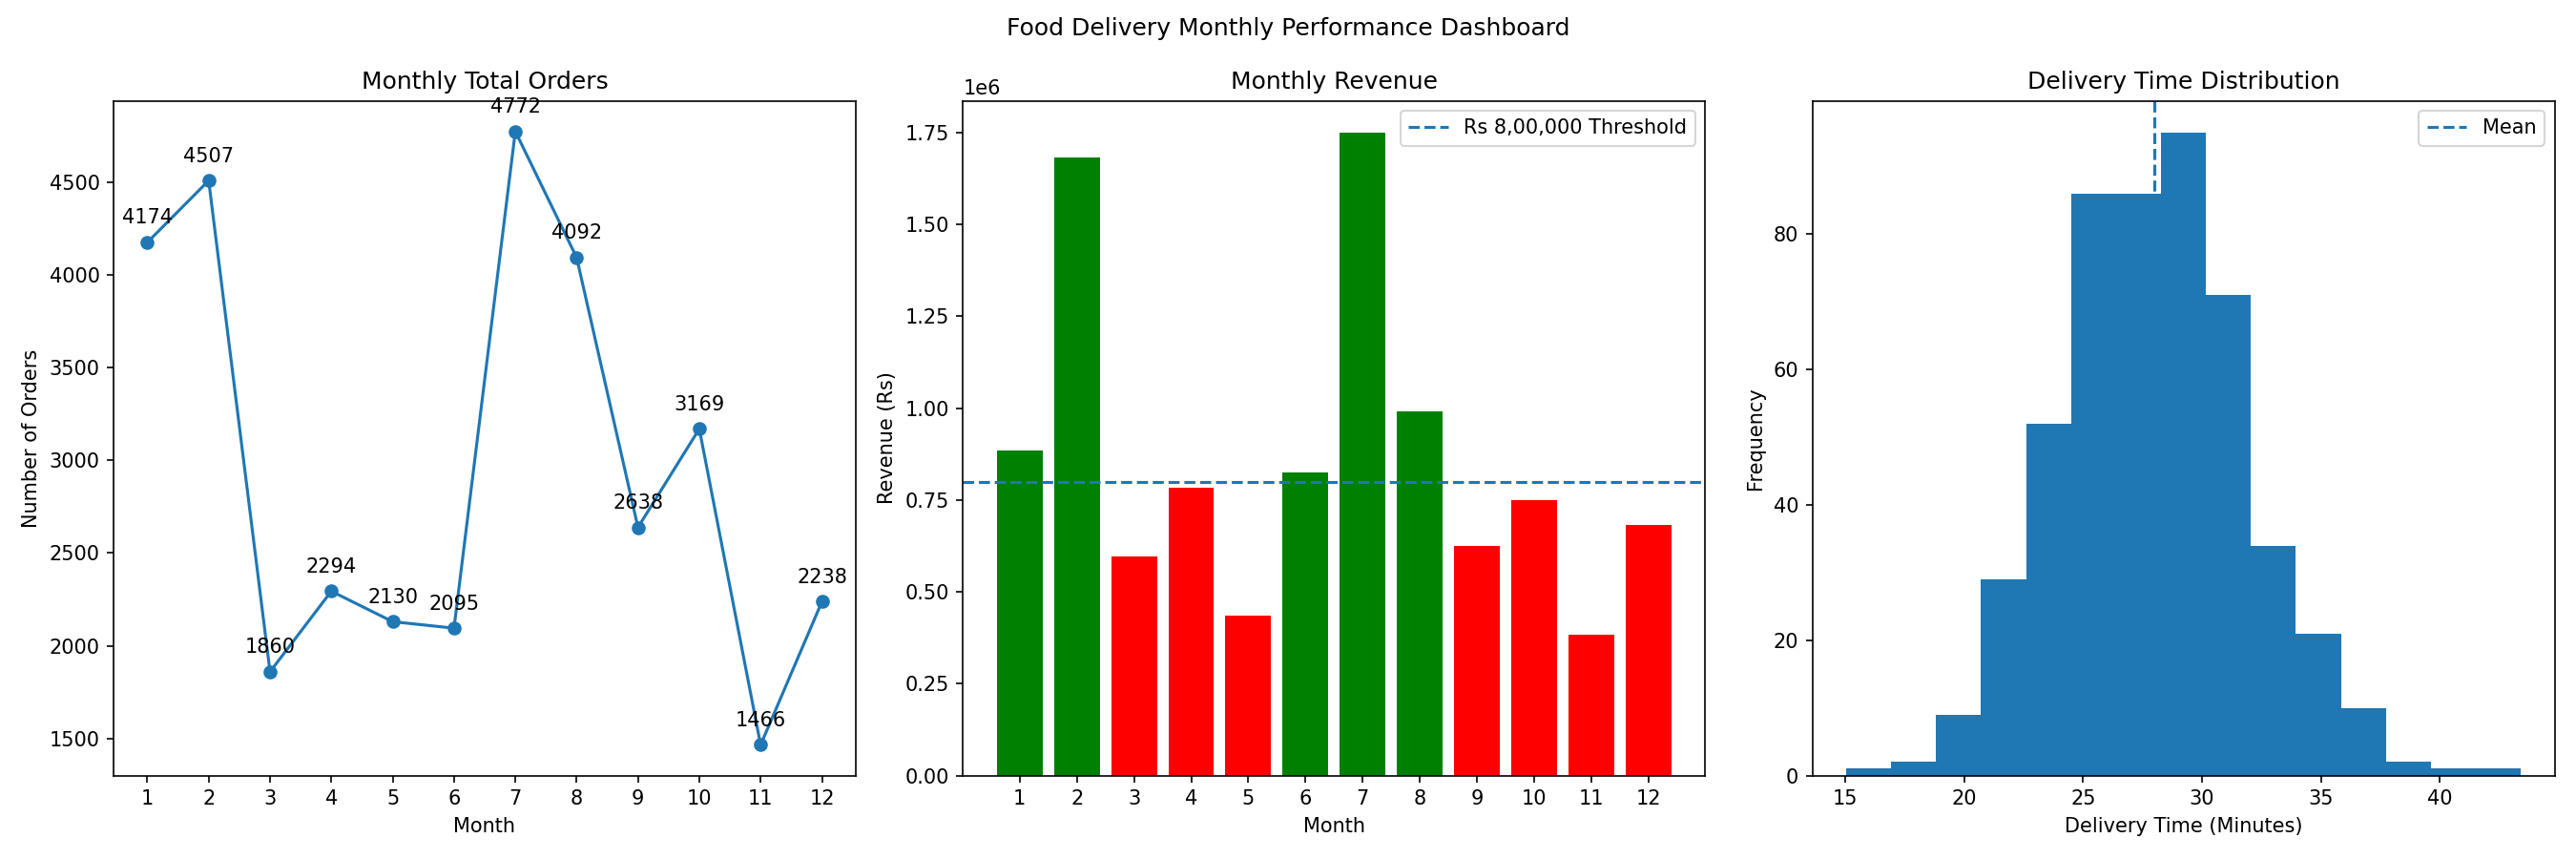

Correlation Heatmap


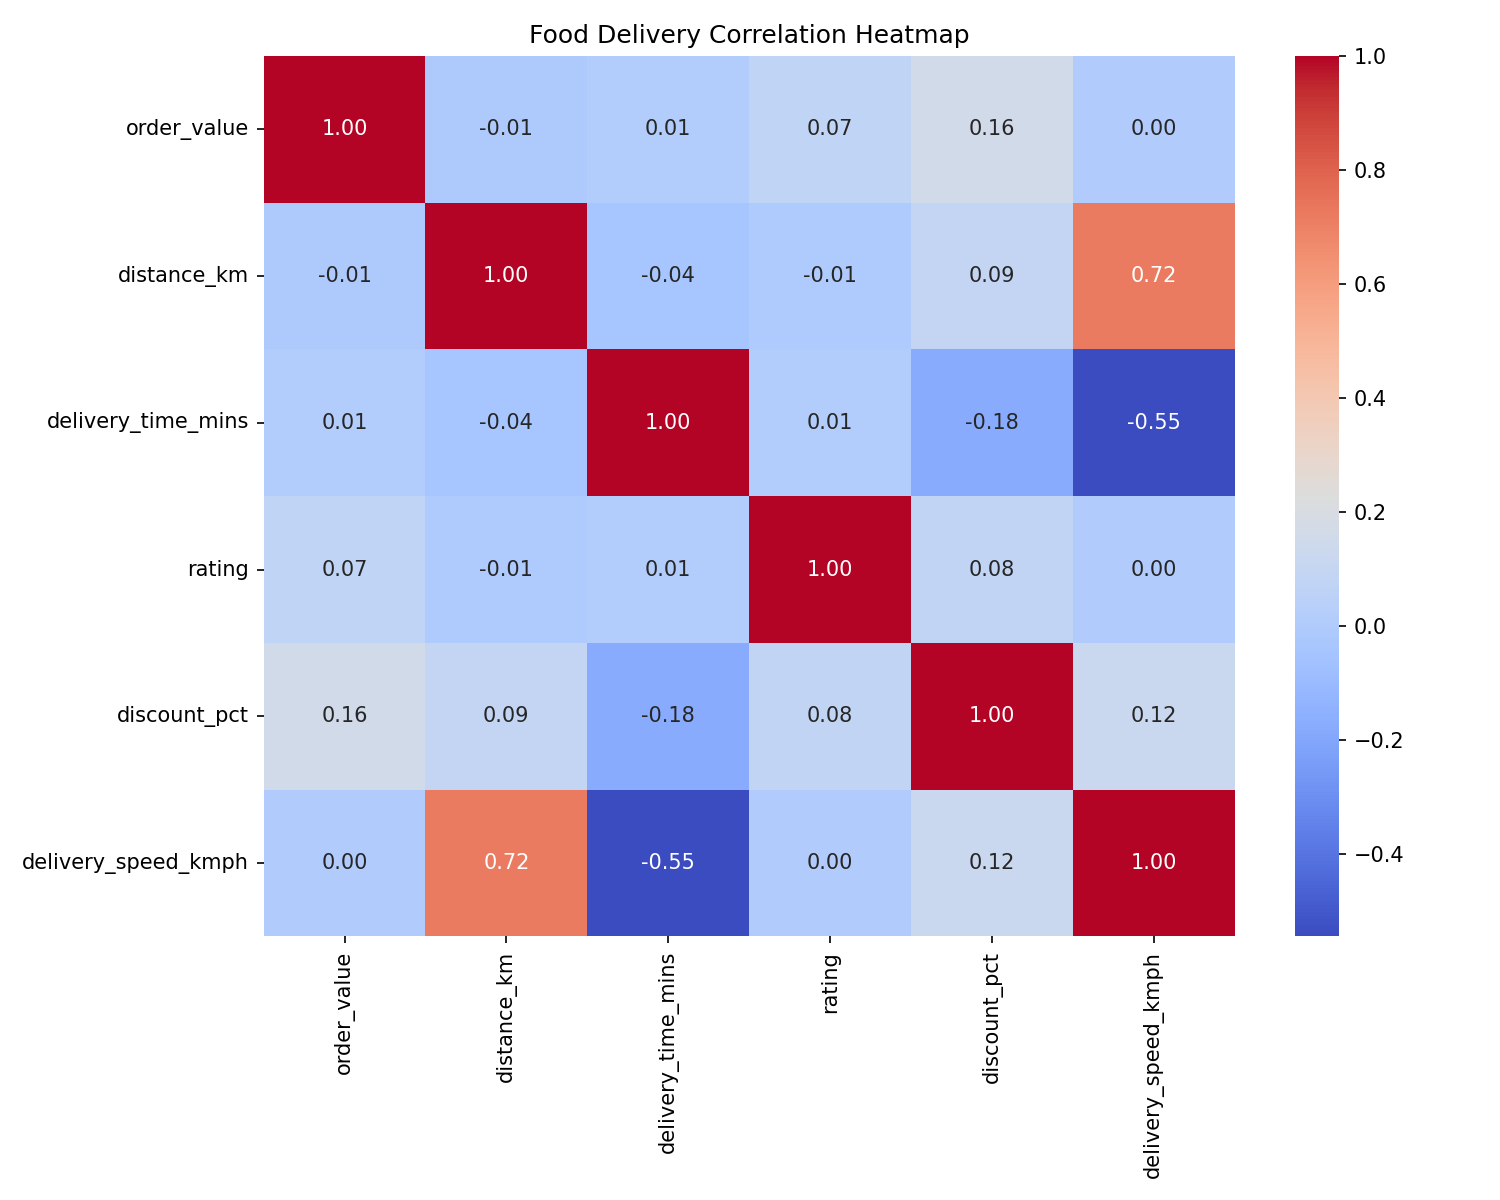

Pairplot


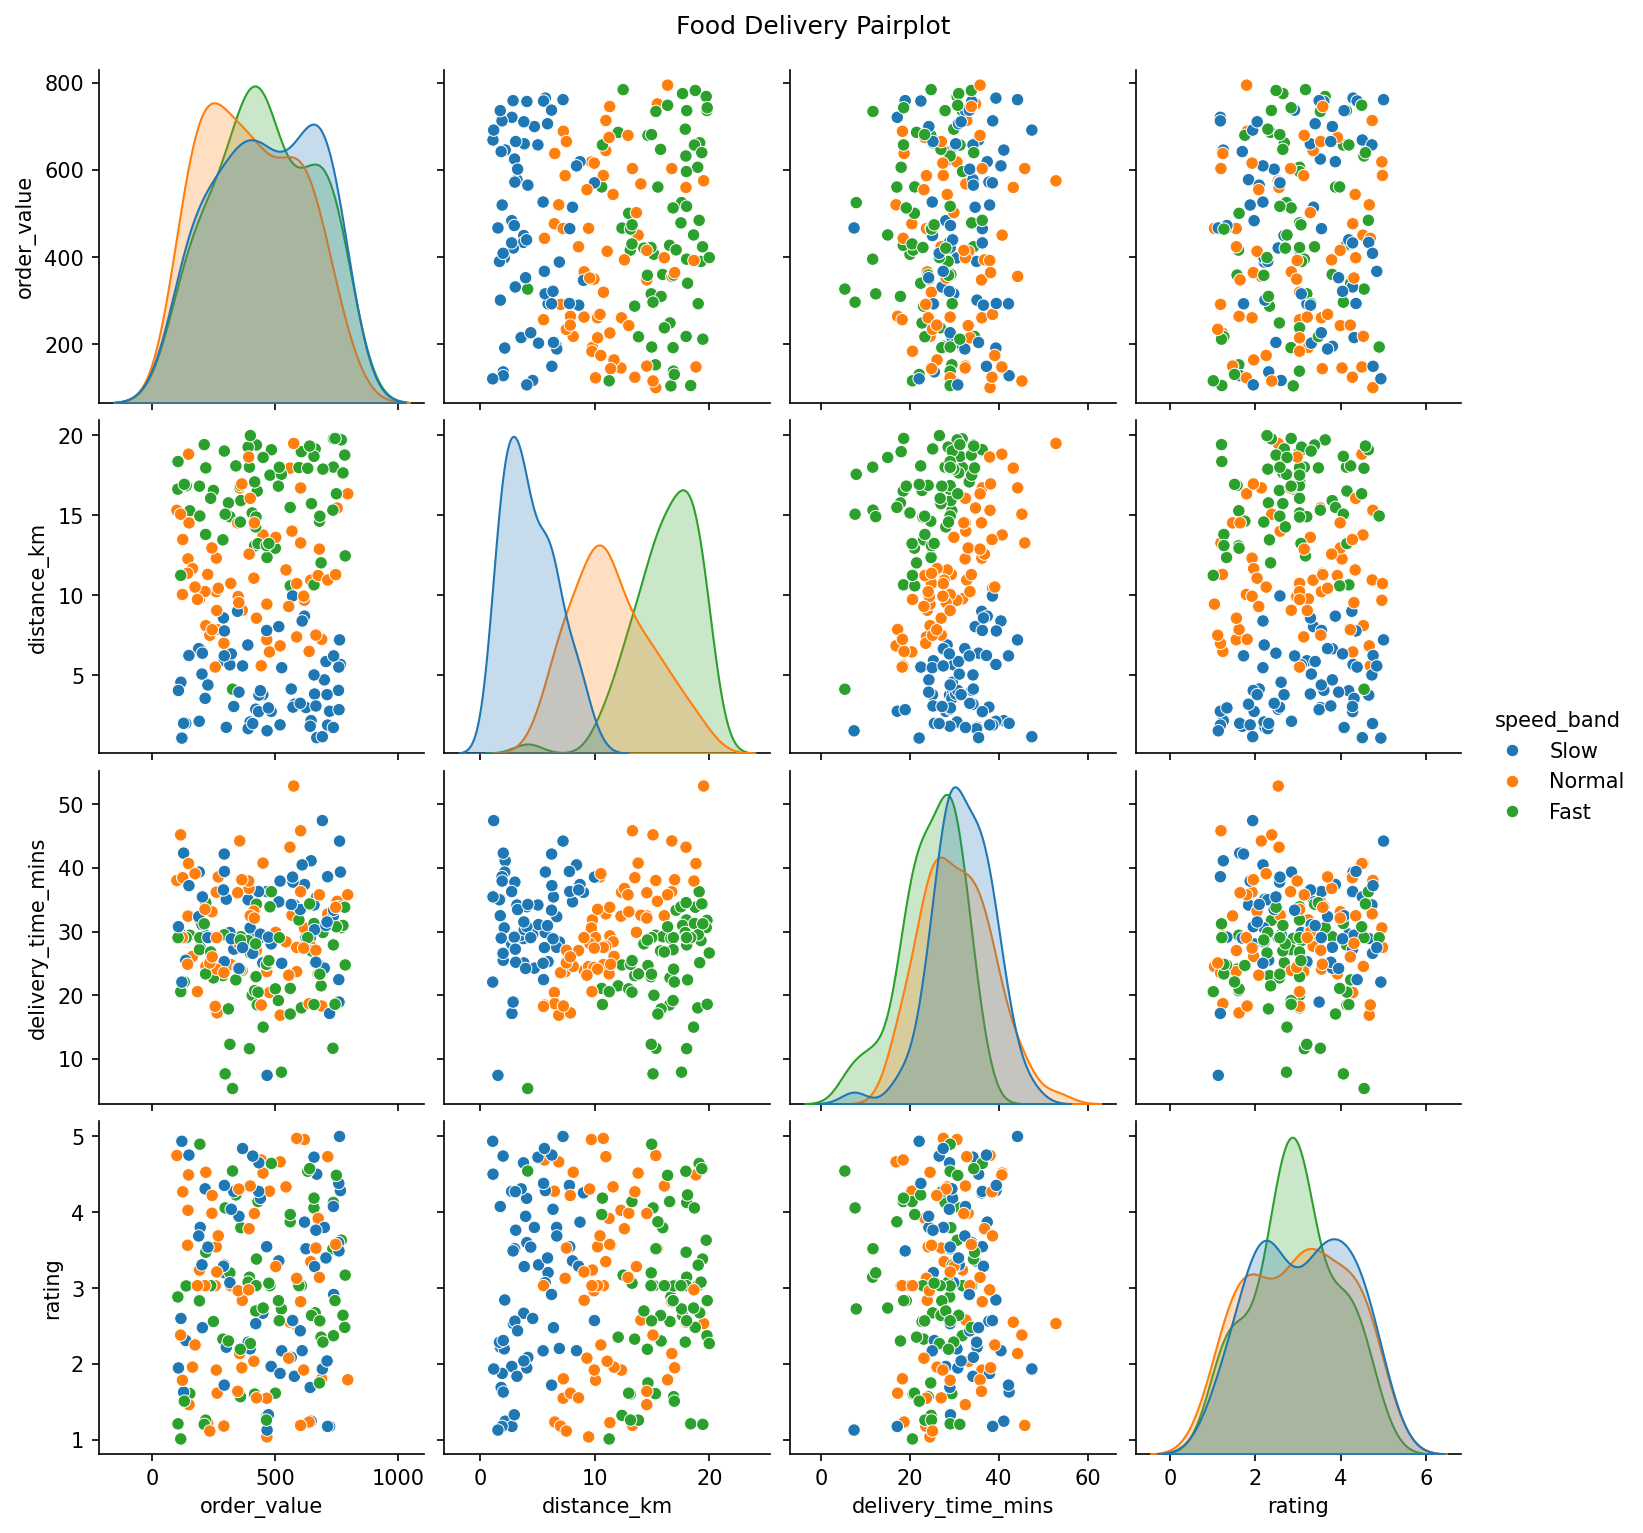

In [5]:
from IPython.display import Image, display

print("Food Delivery Dashboard")
display(Image(filename="food_delivery_dashboard.png"))

print("Correlation Heatmap")
display(Image(filename="correlation_heatmap.png"))

print("Pairplot")
display(Image(filename="pairplot.png"))